# **Eliminación backward con elastic net y AIC (datos imputados)**

El mismo procedimiento de `backward_elastic_net.ipynb`, aplicado a las 20 bases
de la imputación múltiple (`imputacion.ipynb`, N = 669 por base). Cada paso se
ajusta en las 20 bases y se decide con los promedios:

1. Se empieza con todas las variables predictoras (las 14 columnas del diseño
   de M3_joint).
2. En cada base se ajusta elastic net eligiendo α y λ por validación cruzada
   (`cv.glmnet()` para cada α, combinación de menor error con `lambda.min`).
3. Una variable cuenta como **en cero** si su coeficiente es exactamente cero
   en al menos la mitad de las bases. Si ninguna lo es, el proceso se detiene.
4. Para cada variable en cero se reajusta el paso 2 sin ella en las 20 bases y
   se calcula el **AIC medio** entre bases, con
   $\text{AIC} = -2 \log L + 2k$ y $k$ = coeficientes distintos de cero más el
   intercepto. Sale la que deja el menor AIC medio.
5. Se vuelve al paso 2 con el modelo reducido; cada base elige α y λ desde cero.

Las 20 bases usan los mismos 10 folds, estratificados por género, y el mismo
preprocesamiento (`learn_mi_preprocessing()`). En la tabla de pasos, α es el
más elegido entre bases (con el número de bases que lo eligen), λ es la mediana
entre bases, y el AIC, *k*, los ceros por base y las métricas de validación
cruzada son promedios entre bases.

## *Carga de paquetes y configuración*

In [1]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(gt)
})

# Parche para que las tablas gt se vean en Jupyter (mismo del EDA)
repr_html.gt_tbl <- function(obj, ...) gt::as_raw_html(obj)
repr_markdown.gt_tbl <- function(obj, ...) NULL
repr_latex.gt_tbl <- function(obj, ...) NULL
for (g in c("repr_html", "repr_markdown", "repr_latex")) {
  registerS3method(g, "gt_tbl", get(paste0(g, ".gt_tbl")), envir = asNamespace("repr"))
}

# Las rutas de config.R son relativas a la raíz del proyecto.
if (!file.exists("myst.yml") && file.exists("../myst.yml")) setwd("..")

if (file.exists(".Renviron")) readRenviron(".Renviron")

source("R/config.R")
source("R/data_prep.R")
source("R/moderation_pipeline.R")
source("R/cross_validation.R")
source("R/elastic_net.R")
source("R/imputed_pipeline.R")
source("R/backward_en.R")

col_morado <- viridisLite::viridis(10, end = 0.8)[1]
col_verde  <- viridisLite::viridis(10, end = 0.8)[10]

## *Bases imputadas y diseño*

In [2]:
bases     <- load_imputed_datasets()
mi_params <- learn_mi_preprocessing(bases)
designs   <- map(prepare_mi(bases, mi_params), build_en_design)

set.seed(SEED)
foldid <- assign_stratified_folds(bases[[1]][[CV_STRATA_VAR]], EN_INNER_FOLDS)

ZERO_SHARE <- 0.5   # proporción mínima de bases con coeficiente cero

cat(sprintf("Bases imputadas: %d\n", length(designs)))
cat(sprintf("Casos por base:  %d\n", nrow(designs[[1]]$x)))
cat(sprintf("Variables:       %d\n", ncol(designs[[1]]$x)))
cat(sprintf("Respuesta:       %s (%s)\n", OUTCOME_VAR,
            if (is_binary_outcome(designs[[1]]$y)) "binaria" else "continua"))
cat(sprintf("α evaluados:     %s\n", paste(EN_ALPHAS, collapse = ", ")))
cat(sprintf("Regla de cero:   coeficiente cero en ≥ %.0f %% de las bases\n", 100 * ZERO_SHARE))

Bases imputadas: 20


Casos por base:  669


Variables:       14


Respuesta:       Entrapment (continua)


α evaluados:     0.1, 0.25, 0.5, 0.75, 1


Regla de cero:   coeficiente cero en ≥ 50 % de las bases


## *Eliminación backward*

In [3]:
res   <- backward_en_mi(designs, foldid, zero_share = ZERO_SHARE)
steps <- res$steps

Paso  1: sale Gender_code:SigOthers_c      AIC medio =  1690.44  en cero = 7
Paso  2: sale MunicipalitySuan             AIC medio =  1689.70  en cero = 6
Paso  3: sale Gender_code:Friends_c        AIC medio =  1689.34  en cero = 5
Paso  4: sale Gender_code:Family_c         AIC medio =  1688.45  en cero = 4
Paso  5: sale EthnicityCaucasian           AIC medio =  1687.79  en cero = 3
Paso  6: sale MunicipalitySanto Tomas      AIC medio =  1687.44  en cero = 2
Paso  7: sale SigOthers_c                  AIC medio =  1687.08  en cero = 1
Paso  8: sale MunicipalityPuerto Colombia  AIC medio =  1686.11  en cero = 0
Fin: ninguna columna queda en cero en al menos 50 % de las bases.


### *Registro de los pasos*

El paso 0 es el modelo completo. En cada paso siguiente, *Eliminada* es la
variable que salió para llegar a ese modelo. *Variables en cero* son las que
quedan en cero en al menos la mitad de las bases; *ceros por base* es el
promedio del número de coeficientes en cero en cada base.

In [4]:
steps %>%
  select(step, n_vars, removed, alpha, alpha_bases, lambda, aic, aic_sd, k, n_zero,
         n_zero_mean, zero_vars, any_of(c("cv_rmse", "cv_r2", "cv_auc", "cv_accuracy"))) %>%
  gt() %>%
  fmt_number(c(lambda, aic, aic_sd), decimals = 4) %>%
  fmt_number(c(k, n_zero_mean), decimals = 2) %>%
  fmt_number(any_of(c("cv_rmse", "cv_r2", "cv_auc", "cv_accuracy")), decimals = 4) %>%
  sub_missing(missing_text = "—") %>%
  cols_label(step = "Paso", n_vars = "Variables", removed = "Eliminada",
             alpha = "α", alpha_bases = "Bases con ese α", lambda = "λ (mediana)",
             aic = "AIC medio", aic_sd = "DE AIC", k = "k medio",
             n_zero = "Coef. en cero", n_zero_mean = "Ceros por base",
             zero_vars = "Variables en cero",
             cv_rmse = "RMSE (CV)", cv_r2 = "R² (CV)") %>%
  tab_style(style = cell_text(weight = "bold"),
            locations = cells_body(rows = aic == min(aic))) %>%
  tab_header(title = "Eliminación backward con elastic net (20 bases imputadas)",
             subtitle = "En negrita, el paso con menor AIC medio")

<div id="ytjkzawvrv" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#ytjkzawvrv table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#ytjkzawvrv thead, #ytjkzawvrv tbody, #ytjkzawvrv tfoot, #ytjkzawvrv tr, #ytjkzawvrv td, #ytjkzawvrv th {
  border-style: none;
}

#ytjkzawvrv p {
  margin: 0;
  padding: 0;
}

#ytjkzawvrv .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#ytjkzawvrv .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#ytjkzawvrv .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#ytjkzawvrv .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#ytjkzawvrv .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#ytjkzawvrv .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#ytjkzawvrv .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#ytjkzawvrv .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#ytjkzawvrv .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#ytjkzawvrv .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#ytjkzawvrv .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#ytjkzawvrv .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#ytjkzawvrv .gt_spanner_row {
  border-bottom-style: hidden;
}

#ytjkzawvrv .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

### *Candidatas evaluadas en cada paso*

AIC medio del elastic net reajustado sin cada variable en cero, y proporción de
bases en que esa variable tenía coeficiente cero. Sale la de menor AIC medio.

In [5]:
res$candidates %>%
  group_by(step) %>%
  mutate(sale = aic == min(aic)) %>%
  ungroup() %>%
  gt(groupname_col = "step") %>%
  fmt_number(aic, decimals = 4) %>%
  fmt_percent(zero_share, decimals = 0) %>%
  text_transform(locations = cells_body(columns = sale),
                 fn = function(x) ifelse(x == "TRUE", "sí", "")) %>%
  cols_label(candidate = "Candidata", zero_share = "Bases en cero",
             aic = "AIC medio sin ella", sale = "Sale") %>%
  tab_header(title = "Candidatas por paso")

<div id="itifbundlz" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#itifbundlz table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#itifbundlz thead, #itifbundlz tbody, #itifbundlz tfoot, #itifbundlz tr, #itifbundlz td, #itifbundlz th {
  border-style: none;
}

#itifbundlz p {
  margin: 0;
  padding: 0;
}

#itifbundlz .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#itifbundlz .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#itifbundlz .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#itifbundlz .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#itifbundlz .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#itifbundlz .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#itifbundlz .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#itifbundlz .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#itifbundlz .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#itifbundlz .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#itifbundlz .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#itifbundlz .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#itifbundlz .gt_spanner_row {
  border-bottom-style: hidden;
}

#itifbundlz .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

## *AIC por paso*

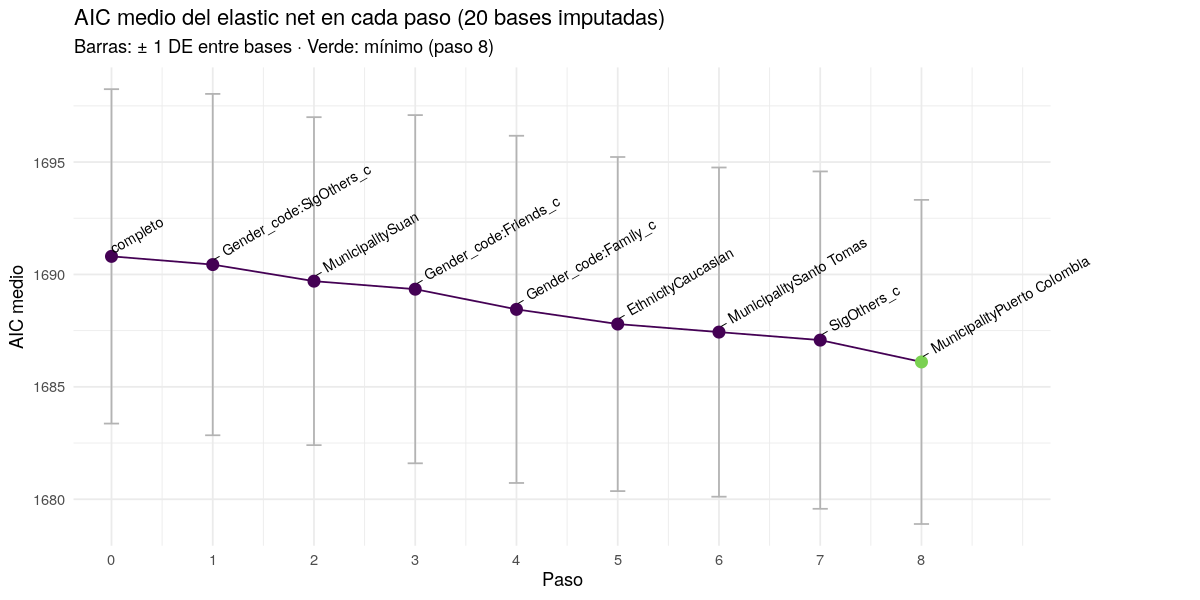

In [6]:
options(repr.plot.width = 10, repr.plot.height = 5)

paso_min <- steps$step[which.min(steps$aic)]

ggplot(steps, aes(x = step, y = aic)) +
  geom_errorbar(aes(ymin = aic - aic_sd, ymax = aic + aic_sd),
                width = 0.15, color = "grey70") +
  geom_line(color = col_morado) +
  geom_point(aes(color = step == paso_min), size = 3, show.legend = FALSE) +
  geom_text(aes(label = ifelse(is.na(removed), "completo", paste("−", removed))),
            angle = 30, hjust = 0, nudge_y = 0.3, size = 3) +
  scale_color_manual(values = c(`FALSE` = col_morado, `TRUE` = col_verde)) +
  scale_x_continuous(breaks = steps$step, expand = expansion(add = c(0.3, 1.2))) +
  labs(title = "AIC medio del elastic net en cada paso (20 bases imputadas)",
       subtitle = sprintf("Barras: ± 1 DE entre bases · Verde: mínimo (paso %d)", paso_min),
       x = "Paso", y = "AIC medio") +
  coord_cartesian(clip = "off") +
  theme_minimal() +
  theme(plot.margin = margin(5.5, 90, 5.5, 5.5))

## *Modelo final*

In [7]:
final <- res$fits[[paso_min + 1]]

cat(sprintf("AIC medio mínimo en el paso %d: %.4f\n", paso_min, final$aic))
cat(sprintf("Variables en el modelo: %d\n", length(final$vars)))

coefs_final <- map_dfr(final$fits, ~ tibble(Variable = names(.x$coef), b = unname(.x$coef)), .id = "imp")

coefs_final %>%
  group_by(Variable) %>%
  summarise(`Bases distinta de cero` = sum(b != 0),
            `Coeficiente medio` = mean(b),
            `Mínimo` = min(b), `Máximo` = max(b),
            .groups = "drop") %>%
  mutate(Variable = factor(Variable, levels = final$vars)) %>%
  arrange(Variable) %>%
  gt() %>%
  fmt_number(c(`Coeficiente medio`, `Mínimo`, `Máximo`), decimals = 4) %>%
  tab_header(title = sprintf("Variables del modelo final (paso %d)", paso_min),
             subtitle = "Coeficientes del elastic net en las 20 bases")

AIC medio mínimo en el paso 8: 1686.1077


Variables en el modelo: 6


<div id="zqmktzinqq" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#zqmktzinqq table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#zqmktzinqq thead, #zqmktzinqq tbody, #zqmktzinqq tfoot, #zqmktzinqq tr, #zqmktzinqq td, #zqmktzinqq th {
  border-style: none;
}

#zqmktzinqq p {
  margin: 0;
  padding: 0;
}

#zqmktzinqq .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#zqmktzinqq .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#zqmktzinqq .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#zqmktzinqq .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#zqmktzinqq .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#zqmktzinqq .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#zqmktzinqq .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#zqmktzinqq .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#zqmktzinqq .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#zqmktzinqq .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#zqmktzinqq .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#zqmktzinqq .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#zqmktzinqq .gt_spanner_row {
  border-bottom-style: hidden;
}

#zqmktzinqq .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

## *Guardado*

- `outputs/tables/mi_backward_en_steps.csv`: registro de los pasos.

In [8]:
dir.create(dirname(PATH_MI_BACKWARD_EN), showWarnings = FALSE, recursive = TRUE)
steps %>%
  select(-zero_share_by) %>%
  mutate(vars = map_chr(vars, paste, collapse = " + ")) %>%
  write_csv(PATH_MI_BACKWARD_EN)
cat(PATH_MI_BACKWARD_EN, "\n")

outputs/tables/mi_backward_en_steps.csv 
